# Member 3 — embedding MLP

Read-only summary of the D-305 saved artifacts. No training or model selection runs here.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RESULT = ROOT / 'reports/results/phase2_member3'
selection = json.loads((RESULT / 'selection.json').read_text())
display(pd.Series({k: selection['winner'][k] for k in ['run', 'learning_rate', 'hidden_dims', 'embedding_cap', 'best_epoch', 'august_pr_auc']}))

run                  run03
learning_rate       0.0001
hidden_dims      [128, 64]
embedding_cap            4
best_epoch               2
august_pr_auc      0.39683
dtype: object

## August tuning and training

All settings and epochs were selected on August PR-AUC.

,run,learning_rate,hidden_dims,embedding_cap,parameters,best_epoch,august_pr_auc
0,run01,0.0001,"[64, 32]",4,11523,2,0.394479
1,run02,0.0001,"[64, 32]",8,16555,3,0.393721
2,run03,0.0001,"[128, 64]",4,23299,2,0.396830
3,run04,0.0001,"[128, 64]",8,29739,3,0.394933
4,run05,0.0003,"[64, 32]",4,11523,1,0.392621
5,run06,0.0003,"[64, 32]",8,16555,2,0.391142
6,run07,0.0003,"[128, 64]",4,23299,1,0.394733
7,run08,0.0003,"[128, 64]",8,29739,1,0.393226


,seed,best_epoch,august_pr_auc
0,42,2,0.396830
1,43,3,0.396788
2,44,2,0.396780
3,45,5,0.397122
4,46,2,0.397724


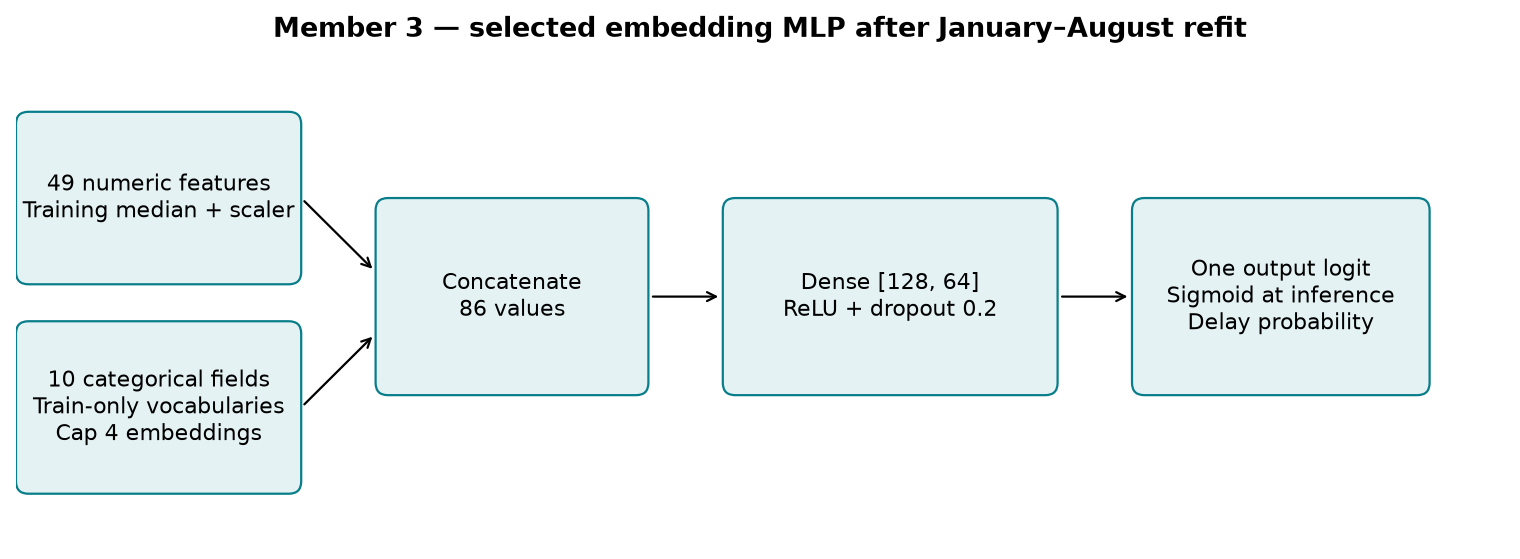

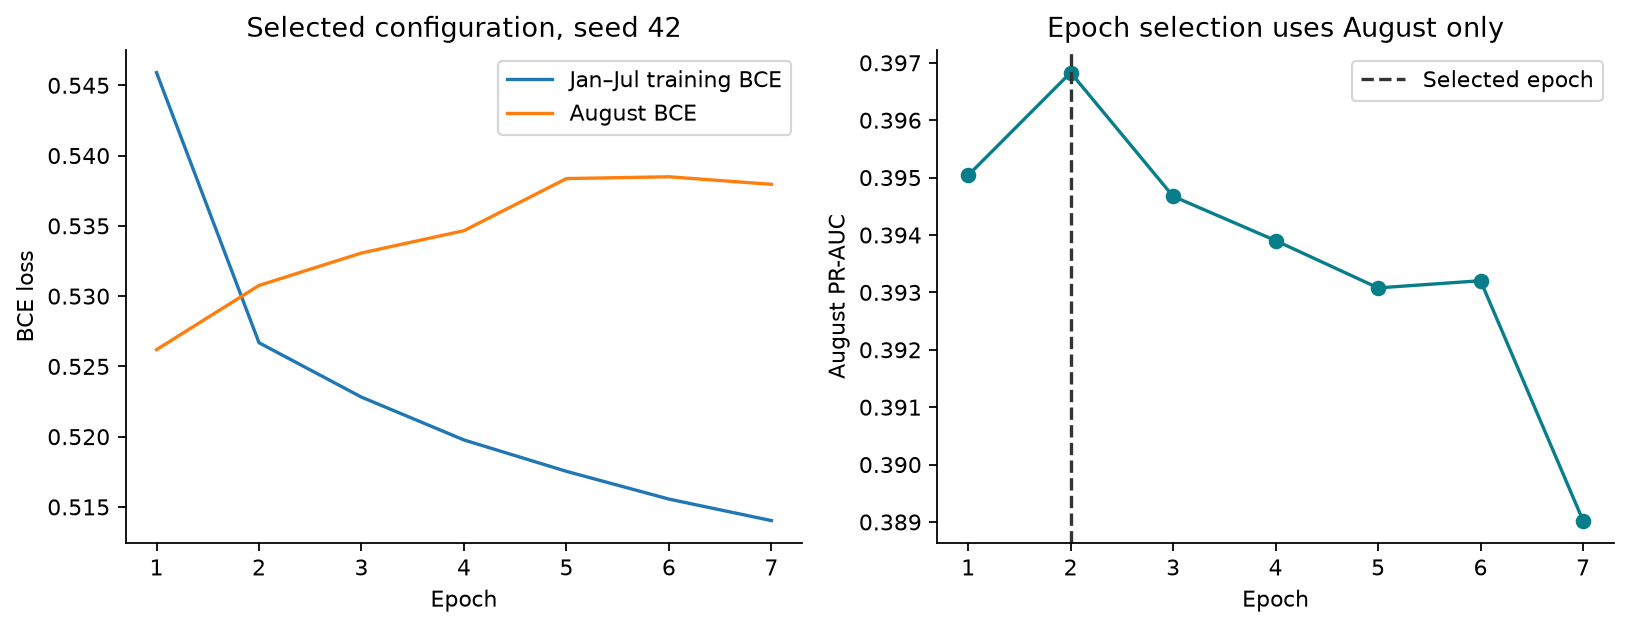

In [2]:
display(pd.read_csv(RESULT / 'grid_august.csv'))
display(pd.read_csv(RESULT / 'august_seed_selection.csv'))
FIGURE = ROOT / 'reports/figures/phase2_member3'
display(Image(filename=str(FIGURE / 'embedding_architecture.png')))
display(Image(filename=str(FIGURE / 'training_curves.png')))

## Frozen September–October comparison

The same 55,628 flights are used for all models. Neural scores are reported across five seeds.

,model,period,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,brier_score_mean,brier_score_std,ece_10_mean,ece_10_std,mean_probability_mean,mean_probability_std
1,embedding,sep_oct,0.276201,0.002424,0.675276,0.001707,0.127935,0.000568,0.047321,0.004378,0.204274,0.004378
4,gru,sep_oct,0.294573,0.005517,0.674338,0.003839,0.136002,0.004672,0.086280,0.014291,0.243231,0.014288
7,lr,sep_oct,0.289590,NaN,0.679999,NaN,0.185537,NaN,0.233413,NaN,0.390366,NaN
10,mlp,sep_oct,0.283929,0.004295,0.671868,0.002738,0.133268,0.002572,0.075744,0.014849,0.232668,0.014859


,comparison,difference,ci_low,ci_high,excludes_zero
0,embedding - mlp,-0.007729,-0.025334,0.011097,False
1,embedding - lr,-0.013389,-0.021208,-0.003450,True
2,embedding - gru,-0.018372,-0.038693,0.001972,False


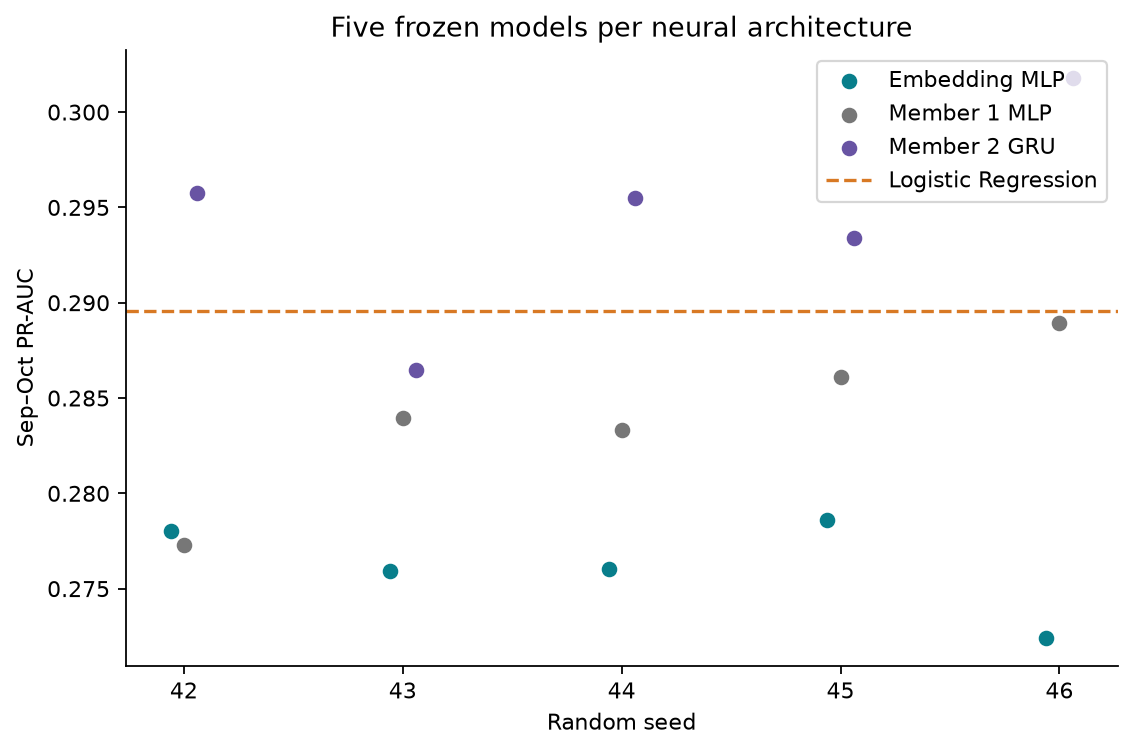

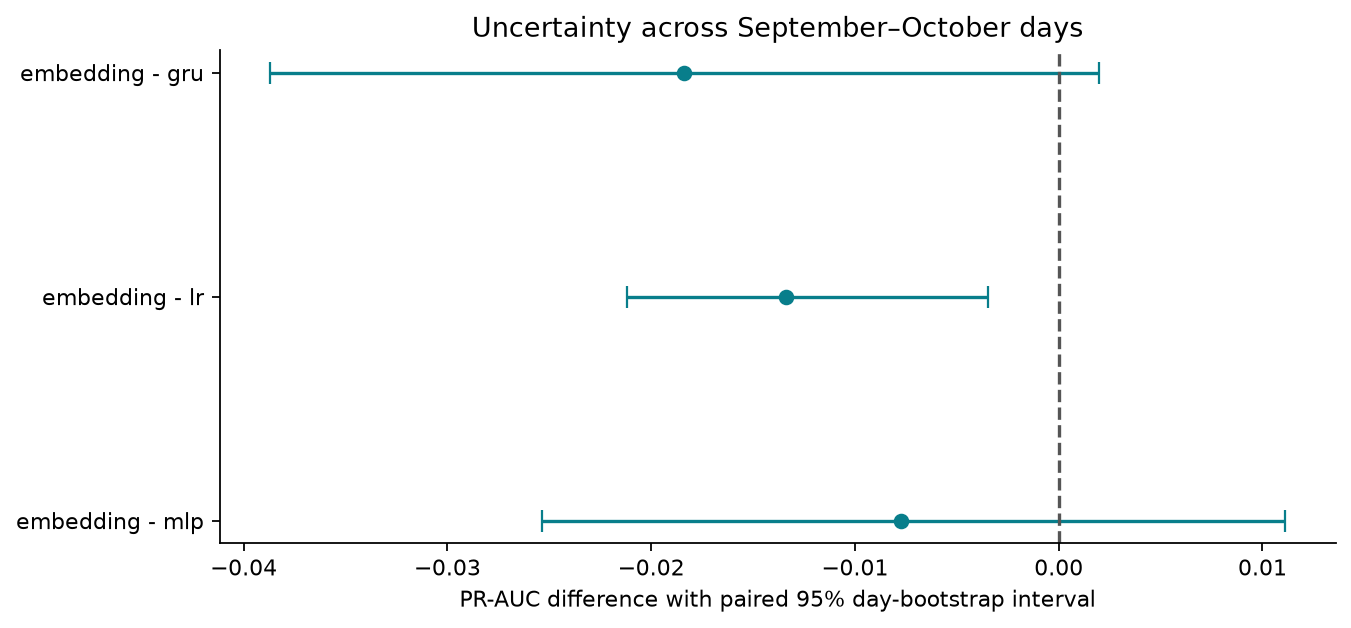

In [3]:
comparison = pd.read_csv(RESULT / 'comparison.csv')
display(comparison.query("period == 'sep_oct'"))
display(pd.read_csv(RESULT / 'bootstrap_pr_auc_differences.csv'))
display(Image(filename=str(FIGURE / 'seed_comparison.png')))
display(Image(filename=str(FIGURE / 'bootstrap_differences.png')))

## Limitations

Raw probabilities require calibration. Evaluation periods were viewed in earlier project iterations. Confidence intervals describe day-level variation for these fixed designs. Full protocol, interpretation and source references are in `docs/phase2_member3_embedding_mlp.md`.